# 01 - Dataset Structure & Data Quality

**Owner:** Efe  |  **Branch:** `eda/data-quality`  |  **Course:** ISE308

**Goal:** get to know the VoltAhead dataset (100 charging stations selected from UrbanEV) and check how far we can trust it before anyone builds features or models on it.

Outputs of this notebook:

| Output | File |
|---|---|
| Dataset summary table | `outputs/tables/dataset_summary.csv` |
| Missing values table | `outputs/tables/missing_values.csv` |
| Station capacity distribution figure | `outputs/figures/station_capacity_distribution.png` |
| Supporting tables / figures | everything else in `outputs/tables/` and `outputs/figures/` |

All data is read through `src/data_loader.py`, so station IDs, the timestamp grid and the development sample are the same for the whole team.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Locate the project root (works whether the kernel starts in notebooks/ or in the root)
ROOT = Path.cwd()
if not (ROOT / "src" / "data_loader.py").exists():
    ROOT = ROOT.parent
sys.path.append(str(ROOT / "src"))
import data_loader as dl

FIG_DIR = ROOT / "outputs" / "figures"
TAB_DIR = ROOT / "outputs" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GRAY, INK = "#257de0", "#f47230", "#9c9c9c", "#191919"
sns.set_theme(style="whitegrid", context="notebook", rc={
    "grid.color": "#e6e6e6", "axes.edgecolor": "#cccccc", "axes.labelcolor": "#444444",
    "text.color": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "figure.facecolor": "white", "axes.facecolor": "white"})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def save_table(df, name, index=False):
    df.to_csv(TAB_DIR / name, index=index)
    return df

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight", facecolor="white")

DATA_ROOT = dl.get_data_root()
print("Project root:", ROOT)
print("Data root   :", DATA_ROOT)

Project root: <project>
Data root   : <project>/data


## 1. Dataset file structure

The dataset is two CSV files:

* `selected_stations.csv` - one row per station (metadata).
* `selected_stations_data.csv` - the 5-minute time series in **long format** (one row per station and time step). The 7 static station columns are repeated on every row, which is why the file is ~300 MB; the loader drops them and serves them from the metadata table instead.

In [2]:
stations_raw = pd.read_csv(dl.stations_path())
data_cols = pd.read_csv(dl.data_path(), nrows=0).columns.tolist()
stored = dl.load_data(reindex=False)          # time series exactly as stored (value columns only)

file_structure = pd.DataFrame([
    {"file": dl.STATIONS_FILE, "size_MB": dl.stations_path().stat().st_size / 1e6,
     "rows": len(stations_raw), "columns": stations_raw.shape[1],
     "description": "Station metadata: coordinates, slow/fast/total charging points, traffic zone (TAZID), distance_km. Sorted by distance_km."},
    {"file": dl.DATA_FILE, "size_MB": dl.data_path().stat().st_size / 1e6,
     "rows": len(stored), "columns": len(data_cols),
     "description": "5-min time series, long format: 10 value columns + 7 static station columns repeated on every row. Sorted by station_id, then time."},
])
save_table(file_structure, "file_structure.csv")
file_structure

,file,size_MB,rows,columns,description
0,selected_stations.csv,0.006,100,8,"Station metadata: coordinates, slow/fast/total..."
1,selected_stations_data.csv,298.486,2592000,19,"5-min time series, long format: 10 value colum..."


## 2. Verifying station, charging point and observation counts

In [3]:
info = dl.load_station_info()
GRID = dl.expected_index()
N_STATIONS, N_STEPS = len(info), len(GRID)

# Static columns repeated in the big file must agree with selected_stations.csv
static_in_data = pd.read_csv(dl.data_path(), usecols=["station_id", *dl.STATIC_COLUMNS])
per_station_unique = static_in_data.groupby("station_id").nunique()
static_constant = bool((per_station_unique.max() == 1).all())
first_static = static_in_data.drop_duplicates("station_id").set_index("station_id").sort_index()
meta = info.set_index("station_id")[dl.STATIC_COLUMNS]
static_equal = {c: bool(np.allclose(first_static[c], meta.loc[first_static.index, c])) for c in dl.STATIC_COLUMNS}
static_na = static_in_data[dl.STATIC_COLUMNS].isna().sum()
del static_in_data

rows_per_station = stored.groupby(level="station_id").size()
ids_data = sorted(stored.index.get_level_values("station_id").unique())

checks = pd.DataFrame([
    ("Stations in selected_stations.csv", N_STATIONS),
    ("Stations in selected_stations_data.csv", len(ids_data)),
    ("Station IDs identical in both files", ids_data == info["station_id"].tolist()),
    ("Traffic zones (TAZID)", info["TAZID"].nunique()),
    ("Charging points: sum of charge_count", int(info["charge_count"].sum())),
    ("   of which slow", int(info["slow_count"].sum())),
    ("   of which fast", int(info["fast_count"].sum())),
    ("slow_count + fast_count == charge_count (all stations)", bool((info.slow_count + info.fast_count == info.charge_count).all())),
    ("First / last timestamp", f"{stored.index.get_level_values('time').min()} / {stored.index.get_level_values('time').max()}"),
    ("Expected 5-min steps per station (2022-12-01 .. 2023-02-28)", N_STEPS),
    ("Rows per station in the data file (unique values)", ", ".join(map(str, sorted(rows_per_station.unique())))),
    ("Rows in the data file", len(stored)),
    ("Expected rows (stations x steps)", N_STATIONS * N_STEPS),
    ("Static columns constant within each station", static_constant),
    ("Static columns equal to selected_stations.csv", all(static_equal.values())),
], columns=["check", "value"])
checks["value"] = checks["value"].astype(str)
checks

,check,value
0,Stations in selected_stations.csv,100
1,Stations in selected_stations_data.csv,100
2,Station IDs identical in both files,True
3,Traffic zones (TAZID),13
4,Charging points: sum of charge_count,1066
5,of which slow,1064
6,of which fast,2
7,slow_count + fast_count == charge_count (all s...,True
8,First / last timestamp,2022-12-01 00:00:00 / 2023-02-28 23:55:00
9,Expected 5-min steps per station (2022-12-01 ....,25920


The two files agree on the 100 stations, every station has exactly the expected 25,920 rows, and the static columns in the big file match the metadata. Note the different ordering: `selected_stations.csv` is sorted by `distance_km`, the data file by `station_id`; always join on `station_id`.

## 3. Columns and data types

In [4]:
head = pd.read_csv(dl.data_path(), nrows=2000)

COL_DOC = {
 "station_id":   "Station key",
 "time":         "Timestamp of the 5-minute interval (start of interval)",
 "busy":         "Number of charging points in use (busy + idle = station capacity)",
 "idle":         "Number of charging points free",
 "s_price":      "Service-fee price (unit not documented in the files; per kWh)",
 "e_price":      "Electricity price (unit not documented in the files; per kWh)",
 "fast_busy":    "Busy fast-charging points",
 "fast_idle":    "Idle fast-charging points",
 "slow_busy":    "Busy slow-charging points",
 "slow_idle":    "Idle slow-charging points",
 "duration":     "Charging time in the interval, in hours, summed over points (0.083 = 5 min of one point) [inferred from values]",
 "volume":       "Energy delivered in the interval, kWh [inferred: 0.583 = 7 kW x 5 min]",
 "longitude":    "Station longitude (static)",
 "latitude":     "Station latitude (static)",
 "slow_count":   "Slow charging points at the station (static)",
 "fast_count":   "Fast charging points at the station (static)",
 "charge_count": "Total charging points = station capacity (static)",
 "TAZID":        "Traffic analysis zone of the station (static)",
 "distance_km":  "Distance of the station to the dataset's reference point, km (static; the point itself is not in the files)",
}
rows = []
for c in head.columns:
    rows.append({"file": dl.DATA_FILE, "column": c, "dtype_as_stored": str(head[c].dtype),
                 "role": "static" if c in dl.STATIC_COLUMNS else ("key" if c in ("station_id", "time") else "value"),
                 "description": COL_DOC[c]})
for c in stations_raw.columns:
    if c not in head.columns:
        rows.append({"file": dl.STATIONS_FILE, "column": c, "dtype_as_stored": str(stations_raw[c].dtype), "role": "static", "description": COL_DOC.get(c, "")})
column_dictionary = save_table(pd.DataFrame(rows), "column_dictionary.csv")
column_dictionary

,file,column,dtype_as_stored,role,description
0,selected_stations_data.csv,station_id,int64,key,Station key
1,selected_stations_data.csv,time,str,key,Timestamp of the 5-minute interval (start of i...
2,selected_stations_data.csv,busy,float64,value,Number of charging points in use (busy + idle ...
3,selected_stations_data.csv,idle,float64,value,Number of charging points free
4,selected_stations_data.csv,s_price,float64,value,Service-fee price (unit not documented in the ...
5,selected_stations_data.csv,e_price,float64,value,Electricity price (unit not documented in the ...
6,selected_stations_data.csv,fast_busy,float64,value,Busy fast-charging points
7,selected_stations_data.csv,fast_idle,float64,value,Idle fast-charging points
8,selected_stations_data.csv,slow_busy,float64,value,Busy slow-charging points
9,selected_stations_data.csv,slow_idle,float64,value,Idle slow-charging points


Note: the CSV stores `time` as text and the counts as floats (`busy`, `idle`, ... are whole numbers stored as `float64` because of the NaNs). The loader parses `time` to `datetime64`, casts IDs to `int` and value columns to `float32`.

## 4. Scan of every station

One pass over the 100 stations collects what the next sections need: duplicates, timestamp coverage, NaN structure, and the busy / idle / capacity consistency checks. The data is read **as stored** (`reindex=False`) so nothing is hidden by the loader.

In [5]:
CAP = info.set_index("station_id")[["charge_count", "fast_count", "slow_count"]]
VALUE_COLS = dl.STATION_COLUMNS
STEPS_PER_DAY = 288
N_DAYS = N_STEPS // STEPS_PER_DAY


def runs(mask):
    '''Lengths of consecutive True runs.'''
    if not mask.any():
        return np.array([], dtype=int)
    edges = np.flatnonzero(np.diff(np.r_[0, mask.astype(np.int8), 0]))
    return edges[1::2] - edges[::2]


def scan_station(sid):
    df = stored.loc[sid]                       # indexed by time, as stored
    idx = df.index
    cap, fcap, scap = CAP.loc[sid]
    r = {"station_id": sid, "n_rows": len(df), "n_unique_ts": idx.nunique(),
         "n_dup_ts": int(idx.duplicated().sum()),
         "n_dup_rows": int(df.reset_index().duplicated().sum()),
         "n_missing_ts": len(GRID.difference(idx)), "n_extra_ts": len(idx.difference(GRID)),
         "sorted": bool(idx.is_monotonic_increasing)}
    for c in VALUE_COLS:
        r[f"na_{c}"] = int(df[c].isna().sum())
    valid = df["busy"].notna().to_numpy()
    r["n_valid"] = int(valid.sum())
    r["n_nan_rows"] = int((~valid).sum())
    r["nan_share"] = r["n_nan_rows"] / len(df)
    if valid.any():
        fv, lv = valid.argmax(), len(valid) - 1 - valid[::-1].argmax()
        gaps = runs(~valid[fv:lv + 1])
        r["leading_nan"], r["trailing_nan"] = int(fv), int(len(valid) - 1 - lv)
    else:
        gaps = np.array([], dtype=int)
        r["leading_nan"], r["trailing_nan"] = len(valid), 0
    r["interior_nan"] = int(gaps.sum())
    r["n_interior_gaps"] = len(gaps)
    r["longest_gap"] = int(gaps.max()) if len(gaps) else 0
    r["reports_on_last_day"] = bool(valid[-STEPS_PER_DAY:].mean() > 0.5)

    v = df[valid]
    tot = v["busy"] + v["idle"]
    r["capacity"] = int(cap)
    r["n_total_ne_cap"] = int((tot != cap).sum())
    r["n_busy_gt_cap"] = int((v["busy"] > cap).sum())
    r["n_negative"] = int((v[["busy", "idle", "fast_busy", "fast_idle", "slow_busy", "slow_idle"]] < 0).sum().sum())
    r["n_noninteger"] = int((v[["busy", "idle"]] % 1 != 0).sum().sum())
    r["n_fastslow_busy_mismatch"] = int(((v["fast_busy"] + v["slow_busy"]) != v["busy"]).sum())
    r["n_fastslow_idle_mismatch"] = int(((v["fast_idle"] + v["slow_idle"]) != v["idle"]).sum())
    r["n_fast_ne_meta"] = int(((v["fast_busy"] + v["fast_idle"]) != fcap).sum())
    r["n_slow_ne_meta"] = int(((v["slow_busy"] + v["slow_idle"]) != scap).sum())
    r["n_negative_price"] = int(((v["s_price"] < 0) | (v["e_price"] < 0)).sum())
    r["mean_occupancy_rate"] = float((v["busy"] / cap).mean()) if len(v) else np.nan
    r["share_time_full"] = float((v["busy"] >= cap).mean()) if len(v) else np.nan
    r["share_time_empty"] = float((v["busy"] == 0).mean()) if len(v) else np.nan
    r["constant_busy"] = bool(v["busy"].nunique() <= 1)
    r["n_s_price_values"] = int(v["s_price"].nunique())
    r["n_e_price_values"] = int(v["e_price"].nunique())
    daily = valid.reshape(N_DAYS, STEPS_PER_DAY).mean(axis=1) if len(valid) == N_STEPS else np.full(N_DAYS, np.nan)
    return r, daily, gaps


results, daily, all_gaps = [], {}, []
for sid in info["station_id"]:
    r, d, g = scan_station(sid)
    results.append(r); daily[sid] = d; all_gaps.append(g)

scan = pd.DataFrame(results).set_index("station_id").join(info.set_index("station_id")[["distance_km", "TAZID", "longitude", "latitude"]])
daily_valid = pd.DataFrame(daily, index=pd.date_range(dl.START, periods=N_DAYS, freq="D")).T
gap_lengths = np.concatenate(all_gaps)
save_table(scan.reset_index(), "station_quality_scan.csv")
print(scan.shape)

(100, 46)


## 5. Duplicates, missing timestamps and missing values

In [6]:
dup_table = pd.DataFrame([
    ("Stations with duplicated timestamps", int((scan.n_dup_ts > 0).sum()), int(scan.n_dup_ts.sum())),
    ("Stations with fully duplicated rows", int((scan.n_dup_rows > 0).sum()), int(scan.n_dup_rows.sum())),
    ("Stations not sorted by time", int((~scan["sorted"]).sum()), None),
    ("Stations with a row count != 25,920", int((scan.n_rows != N_STEPS).sum()), None),
    ("Stations with timestamps missing from the expected grid", int((scan.n_missing_ts > 0).sum()), int(scan.n_missing_ts.sum())),
    ("Stations with timestamps outside the expected grid", int((scan.n_extra_ts > 0).sum()), int(scan.n_extra_ts.sum())),
], columns=["check", "stations_affected", "rows_affected"])
save_table(dup_table, "duplicates_and_timestamps.csv")
dup_table

,check,stations_affected,rows_affected
0,Stations with duplicated timestamps,0,0.000
1,Stations with fully duplicated rows,0,0.000
2,Stations not sorted by time,0,NaN
3,"Stations with a row count != 25,920",0,NaN
4,Stations with timestamps missing from the expe...,0,0.000
5,Stations with timestamps outside the expected ...,0,0.000


In [7]:
# Missing values per column
total_rows = int(scan.n_rows.sum())
missing_values = pd.DataFrame({
    "column": VALUE_COLS,
    "n_missing": [int(scan[f"na_{c}"].sum()) for c in VALUE_COLS],
    "total_rows": total_rows,
})
missing_values["missing_share"] = missing_values["n_missing"] / total_rows
static_missing = pd.DataFrame({"column": dl.STATIC_COLUMNS, "n_missing": static_na.reindex(dl.STATIC_COLUMNS).to_numpy(),
                               "total_rows": total_rows})
static_missing["missing_share"] = static_missing["n_missing"] / total_rows
missing_values = save_table(pd.concat([missing_values, static_missing], ignore_index=True), "missing_values.csv")
missing_values

,column,n_missing,total_rows,missing_share
0,busy,660016,2592000,0.255
1,idle,660016,2592000,0.255
2,s_price,660016,2592000,0.255
3,e_price,660016,2592000,0.255
4,fast_busy,660016,2592000,0.255
5,fast_idle,660016,2592000,0.255
6,slow_busy,660016,2592000,0.255
7,slow_idle,660016,2592000,0.255
8,duration,660016,2592000,0.255
9,volume,660016,2592000,0.255


In [8]:
all_na_rows = int(scan.n_nan_rows.sum())
same_pattern = all(scan[f"na_{c}"].equals(scan["na_busy"]) for c in VALUE_COLS)
print(f"Rows where every value column is NaN : {all_na_rows:,} of {total_rows:,} ({all_na_rows/total_rows:.1%})")
print(f"All 10 value columns have exactly the same NaN count in every station: {same_pattern}")
print(f"Stations with at least one NaN row   : {(scan.n_nan_rows > 0).sum()} of {len(scan)}")
print(f"Stations that are 100% NaN           : {(scan.n_valid == 0).sum()}")

Rows where every value column is NaN : 660,016 of 2,592,000 (25.5%)
All 10 value columns have exactly the same NaN count in every station: True
Stations with at least one NaN row   : 56 of 100
Stations that are 100% NaN           : 1


The files are *complete in rows* (no duplicates, no missing timestamps), but a missing observation is stored as a **row whose 10 value columns are all NaN**. Missingness is therefore a station-level event (a station not reporting), never a single column.

### 5.1 Where do the NaN rows sit, and how many stations are affected?

In [9]:
comp = pd.Series({
    "Leading (before the station's first report)": int(scan.leading_nan.sum()),
    "Interior (gaps between first and last report)": int(scan.interior_nan.sum()),
    "Trailing (after the station's last report)": int(scan.trailing_nan.sum()),
})
comp_df = pd.DataFrame({"nan_rows": comp, "share_of_all_nan": comp / comp.sum(), "share_of_all_rows": comp / total_rows})
save_table(comp_df.reset_index().rename(columns={"index": "type"}), "missing_composition.csv")
display(comp_df)

bins = [-0.001, 0.0, 0.01, 0.10, 0.25, 0.50, 0.999, 1.0]
labels = ["0 %", "0-1 %", "1-10 %", "10-25 %", "25-50 %", "50-99.9 %", "100 %"]
dist = scan.groupby(pd.cut(scan.nan_share, bins=bins, labels=labels), observed=False).size().rename("stations").to_frame()
save_table(dist.reset_index().rename(columns={"nan_share": "nan_share_bucket"}), "missing_share_by_station.csv")
display(dist)

# How many stations survive a coverage filter?
thr = pd.DataFrame({"max_nan_share": [0.0, 0.01, 0.10, 0.30, 0.50]})
thr["stations_kept"] = [int((scan.nan_share <= t).sum()) for t in thr.max_nan_share]
thr["charging_points_kept"] = [int(scan.loc[scan.nan_share <= t, "capacity"].sum()) for t in thr.max_nan_share]
extra = pd.DataFrame({"max_nan_share": ["reports on the last day"], "stations_kept": [int(scan.reports_on_last_day.sum())],
                      "charging_points_kept": [int(scan.loc[scan.reports_on_last_day, "capacity"].sum())]})
coverage_filters = save_table(pd.concat([thr.astype({"max_nan_share": object}), extra], ignore_index=True), "station_coverage_filters.csv")
display(coverage_filters)

,nan_rows,share_of_all_nan,share_of_all_rows
Leading (before the station's first report),144342,0.219,0.056
Interior (gaps between first and last report),412052,0.624,0.159
Trailing (after the station's last report),103622,0.157,0.040


,stations
nan_share,
0 %,44
0-1 %,5
1-10 %,0
10-25 %,1
25-50 %,40
50-99.9 %,9
100 %,1


,max_nan_share,stations_kept,charging_points_kept
0,0.000,44,337
1,0.010,49,448
2,0.100,49,448
3,0.300,50,459
4,0.500,90,792
5,reports on the last day,52,505


### 5.2 Missing timestamps and gap lengths

No timestamp is missing from the grid, so the "missing timestamps" that matter are the NaN gaps. The next table shows how long the interior gaps are (leading and trailing NaN are not gaps: the station was not yet or no longer reporting).

In [10]:
steps = {"5 min": 1, "1 hour": 12, "6 hours": 72, "1 day": 288, "1 week": 2016}
gap_summary = pd.DataFrame([
    {"gap_at_least": k, "n_gaps": int((gap_lengths >= v).sum()),
     "stations_with_such_a_gap": int((scan.longest_gap >= v).sum())}
    for k, v in steps.items()])
save_table(gap_summary, "gap_length_summary.csv")
display(gap_summary)
print(f"Interior gaps in total: {len(gap_lengths)}; median length {np.median(gap_lengths):.0f} steps "
      f"({np.median(gap_lengths)/288:.1f} days); longest {gap_lengths.max():,} steps ({gap_lengths.max()/288:.1f} days)")
print(f"Median over stations (with an interior gap) of their longest gap: "
      f"{scan.longest_gap[scan.longest_gap > 0].median():.0f} steps ({scan.longest_gap[scan.longest_gap > 0].median()/288:.1f} days)")

,gap_at_least,n_gaps,stations_with_such_a_gap
0,5 min,358,55
1,1 hour,338,50
2,6 hours,252,50
3,1 day,247,50
4,1 week,45,42


Interior gaps in total: 358; median length 1291 steps (4.5 days); longest 8,774 steps (30.5 days)
Median over stations (with an interior gap) of their longest gap: 2861 steps (9.9 days)


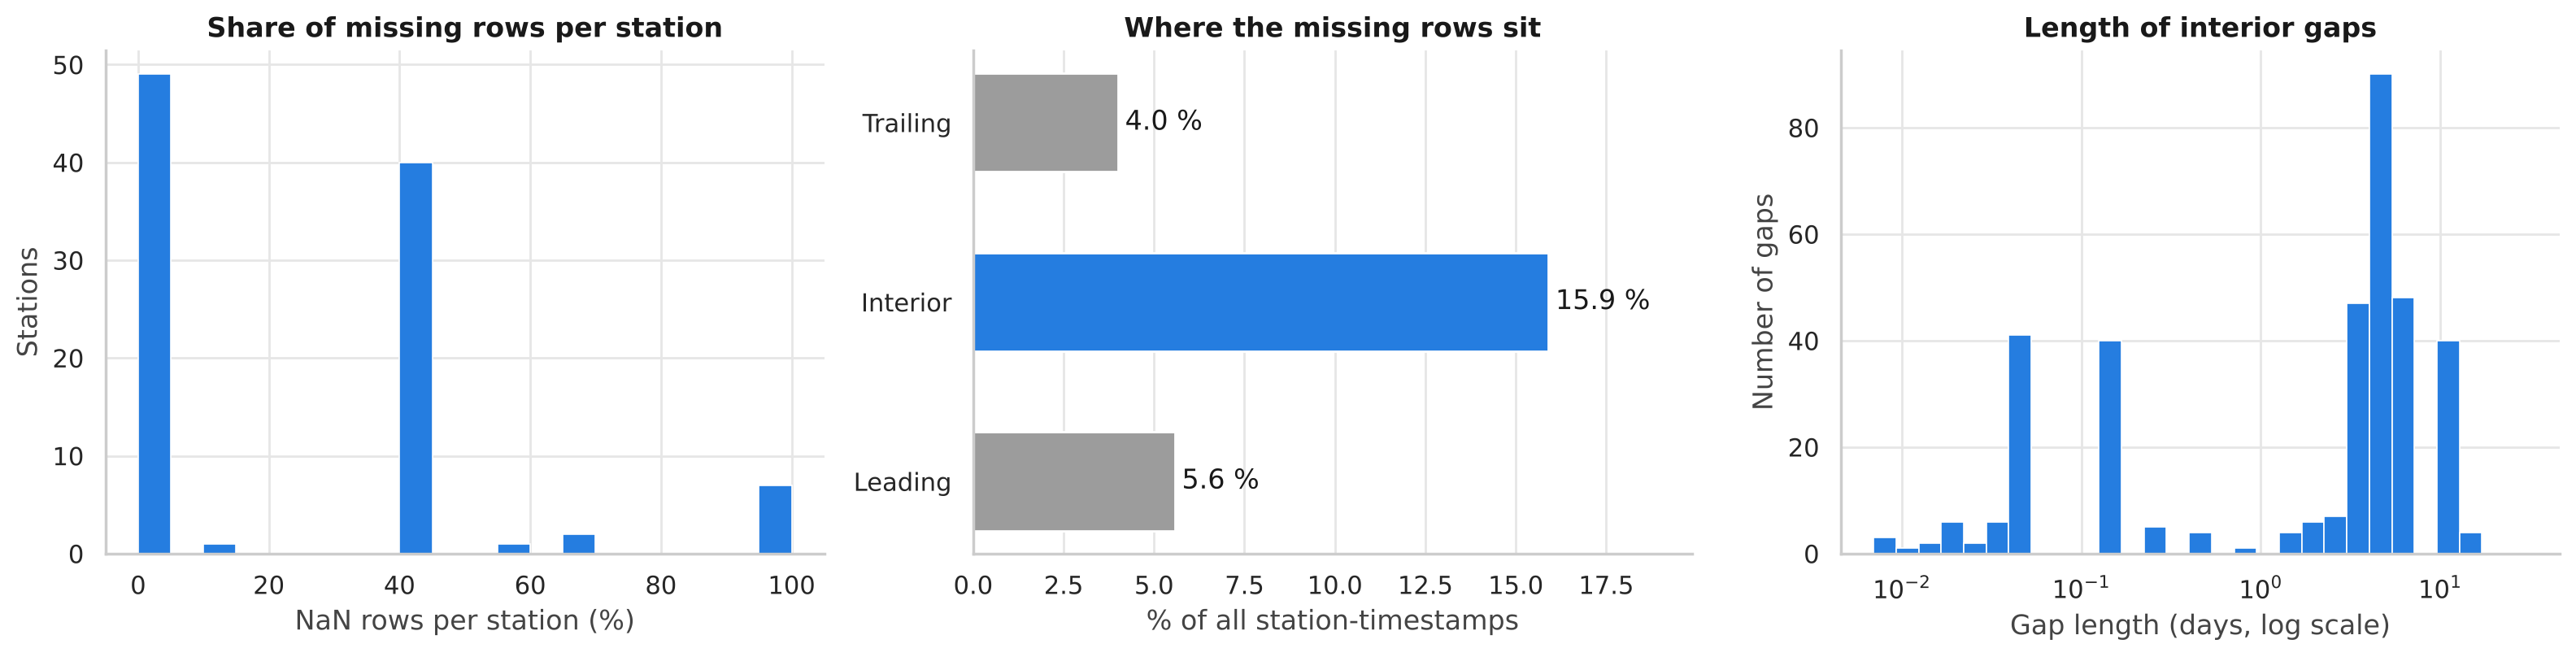

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

ax = axes[0]
ax.hist(scan.nan_share * 100, bins=np.arange(0, 105, 5), color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_xlabel("NaN rows per station (%)"); ax.set_ylabel("Stations")
ax.set_title("Share of missing rows per station")

ax = axes[1]
parts = scan[["leading_nan", "interior_nan", "trailing_nan"]].sum() / total_rows * 100
ax.barh(["Leading", "Interior", "Trailing"], parts.values, color=[GRAY, BLUE, GRAY], height=0.55)
for y, v in enumerate(parts.values):
    ax.text(v + 0.2, y, f"{v:.1f} %", va="center", color=INK)
ax.set_xlabel("% of all station-timestamps"); ax.set_title("Where the missing rows sit")
ax.set_xlim(0, parts.max() * 1.25); ax.grid(axis="y", visible=False)

ax = axes[2]
ax.hist(gap_lengths / 288, bins=np.logspace(np.log10(max(gap_lengths.min(), 1) / 288), np.log10(gap_lengths.max() / 288), 30), color=BLUE, edgecolor="white", linewidth=0.6)
ax.set_xscale("log"); ax.set_xlabel("Gap length (days, log scale)"); ax.set_ylabel("Number of gaps")
ax.set_title("Length of interior gaps")
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "missing_overview.png")
plt.show()

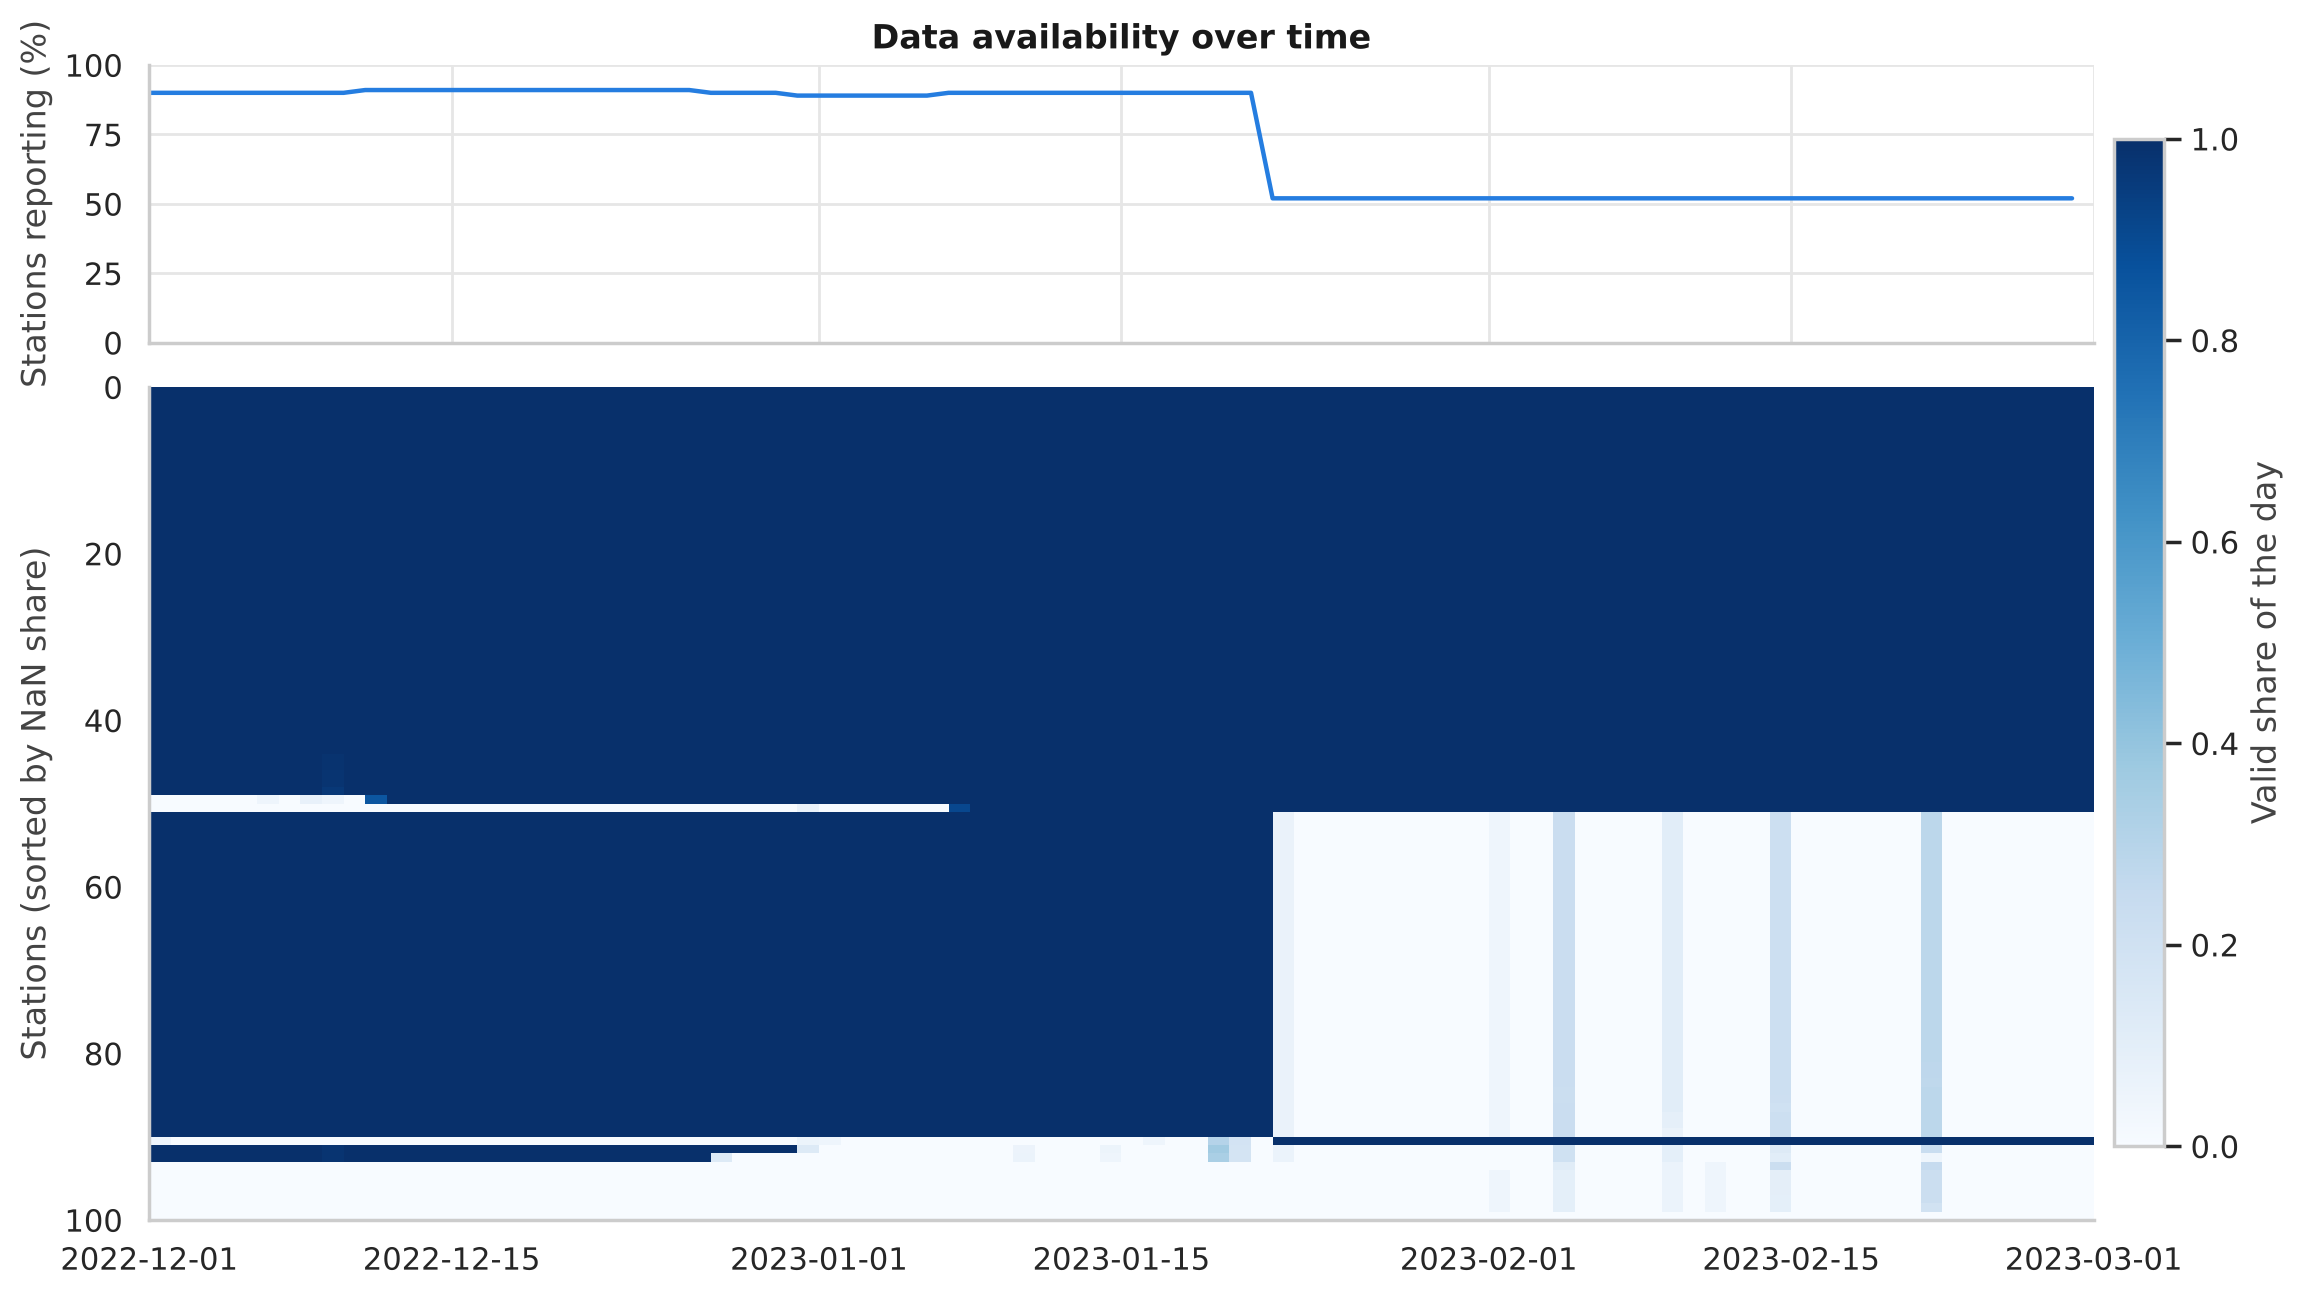

In [12]:
# Data availability over time: fraction of valid 5-min steps per station per day
order = scan.sort_values("nan_share").index
fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True,
                               gridspec_kw={"height_ratios": [1, 3], "hspace": 0.08})
share_reporting = (daily_valid > 0.5).mean()
ax0.plot(share_reporting.index, share_reporting.values * 100, color=BLUE, linewidth=1.6)
ax0.set_ylabel("Stations reporting (%)"); ax0.set_ylim(0, 100)
ax0.set_title("Data availability over time")
im = ax1.imshow(daily_valid.loc[order].values, aspect="auto", cmap="Blues", vmin=0, vmax=1,
                extent=[mdates.date2num(daily_valid.columns[0]),
                        mdates.date2num(daily_valid.columns[-1]) + 1, len(order), 0])
ax1.xaxis_date(); ax1.set_ylabel("Stations (sorted by NaN share)")
ax1.grid(False)
cb = fig.colorbar(im, ax=[ax0, ax1], pad=0.01, fraction=0.025); cb.set_label("Valid share of the day")
for a in (ax0, ax1): a.spines[["top", "right"]].set_visible(False)
save_fig(fig, "data_availability_heatmap.png")
plt.show()

The heatmap shows that missingness is **not random**: the share of stations that report changes in one step on a single day. The next cell locates that event and shows how it splits the period.

In [13]:
rep = (daily_valid > 0.5).mean()                 # share of stations reporting on each day
jumps = rep.diff()[lambda s: s.abs() > 0.10]
events = pd.DataFrame({"date": jumps.index.date, "change_in_share_reporting": jumps.values})
events["share_reporting_after"] = rep.loc[jumps.index].values
save_table(events, "reporting_events.csv")
display(events)

EVENT = jumps.index[0] if len(jumps) else None
monthly = (1 - (daily_valid.T).groupby(pd.Grouper(freq="MS")).mean().T.mean()).rename("nan_share").to_frame()
monthly.index = monthly.index.strftime("%Y-%m")
save_table(monthly.reset_index().rename(columns={"time": "month", "index": "month"}), "nan_share_by_month.csv")
display(monthly)

if EVENT is not None:
    before, after = daily_valid.loc[:, :EVENT - pd.Timedelta(days=1)], daily_valid.loc[:, EVENT:]
    print(f"Event date: {EVENT.date()}")
    print(f"Share of stations reporting: {rep.loc[:EVENT - pd.Timedelta(days=1)].iloc[-1]:.0%} the day before, {rep.loc[EVENT]:.0%} on the day, {rep.iloc[-1]:.0%} on the last day")
    print(f"NaN share of all station-days: {1 - before.values.mean():.1%} before the event, {1 - after.values.mean():.1%} from the event to the end")
    print(f"Stations that are > 50 % NaN from the event on: {(after.mean(axis=1) < 0.5).sum()} of {len(after)}")
    print(f"Days before the event: {before.shape[1]}, days from the event on: {after.shape[1]}")

,date,change_in_share_reporting,share_reporting_after
0,2023-01-22,-0.380,0.520


,nan_share
2022-12,0.095
2023-01,0.223
2023-02,0.466


Event date: 2023-01-22
Share of stations reporting: 90% the day before, 52% on the day, 52% on the last day
NaN share of all station-days: 9.8% before the event, 46.9% from the event to the end
Stations that are > 50 % NaN from the event on: 48 of 100
Days before the event: 52, days from the event on: 38


## 6. Consistency of `busy`, `idle` and station capacity

All checks use only valid rows (NaN rows are excluded, otherwise every comparison would fail trivially).

In [14]:
n_valid_total = int(scan.n_valid.sum())
def row(name, col):
    return {"check": name, "rows_violating": int(scan[col].sum()),
            "stations_violating": int((scan[col] > 0).sum()), "valid_rows_checked": n_valid_total}
cons = pd.DataFrame([
    row("busy + idle != charge_count (station capacity)", "n_total_ne_cap"),
    row("busy > charge_count", "n_busy_gt_cap"),
    row("negative busy / idle / fast / slow counts", "n_negative"),
    row("non-integer busy or idle", "n_noninteger"),
    row("fast_busy + slow_busy != busy", "n_fastslow_busy_mismatch"),
    row("fast_idle + slow_idle != idle", "n_fastslow_idle_mismatch"),
    row("fast_busy + fast_idle != fast_count (metadata)", "n_fast_ne_meta"),
    row("slow_busy + slow_idle != slow_count (metadata)", "n_slow_ne_meta"),
    row("negative price", "n_negative_price"),
])
cons["verdict"] = np.where(cons.rows_violating == 0, "OK", "CHECK")
save_table(cons, "consistency_checks.csv")
cons

,check,rows_violating,stations_violating,valid_rows_checked,verdict
0,busy + idle != charge_count (station capacity),0,0,1931984,OK
1,busy > charge_count,0,0,1931984,OK
2,negative busy / idle / fast / slow counts,0,0,1931984,OK
3,non-integer busy or idle,0,0,1931984,OK
4,fast_busy + slow_busy != busy,0,0,1931984,OK
5,fast_idle + slow_idle != idle,0,0,1931984,OK
6,fast_busy + fast_idle != fast_count (metadata),0,0,1931984,OK
7,slow_busy + slow_idle != slow_count (metadata),0,0,1931984,OK
8,negative price,0,0,1931984,OK


`busy + idle` equals the station capacity in **every valid row**, so occupancy rate `busy / charge_count` and availability `idle` are exactly consistent, and the fast/slow split agrees with the metadata.

### 6.1 Suspicious stations and price columns

In [15]:
fast_stations = info[info.fast_count > 0]
susp = pd.DataFrame([
    ("100 % NaN (never report)", int((scan.n_valid == 0).sum())),
    ("Report but `busy` never changes", int(((scan.constant_busy) & (scan.n_valid > 0)).sum())),
    ("Empty (busy == 0) more than 90 % of their valid time", int((scan.share_time_empty > 0.9).sum())),
    ("Full (busy == capacity) more than 50 % of their valid time", int((scan.share_time_full > 0.5).sum())),
    ("Stations with at least one fast-charging point", len(fast_stations)),
    ("Fast-charging points in the whole dataset", int(info.fast_count.sum())),
    ("Share of valid observations where the station is completely full", float((scan.share_time_full * scan.n_valid).sum() / scan.n_valid.sum())),
    ("Share of valid observations where the station is completely empty", float((scan.share_time_empty * scan.n_valid).sum() / scan.n_valid.sum())),
    ("Mean occupancy rate (busy / capacity) over valid observations", float((scan.mean_occupancy_rate * scan.n_valid).sum() / scan.n_valid.sum())),
    ("Stations whose s_price takes more than 1 value", int((scan.n_s_price_values > 1).sum())),
    ("Stations whose e_price takes more than 1 value", int((scan.n_e_price_values > 1).sum())),
], columns=["check", "value"])
save_table(susp, "suspicious_stations.csv")
display(susp)

vals = stored.dropna(subset=["busy"])
for col in ("s_price", "e_price"):
    x = vals[col].astype("float64").round(3)
    print(f"{col}: {x.nunique()} distinct values overall, range {x.min():.3f} - {x.max():.3f}; "
          f"values per station: median {int(scan['n_' + col.split('_')[0] + '_price_values'].median())}, max {int(scan['n_' + col.split('_')[0] + '_price_values'].max())}")

,check,value
0,100 % NaN (never report),1.000
1,Report but `busy` never changes,0.000
2,Empty (busy == 0) more than 90 % of their vali...,10.000
3,Full (busy == capacity) more than 50 % of thei...,4.000
4,Stations with at least one fast-charging point,1.000
5,Fast-charging points in the whole dataset,2.000
6,Share of valid observations where the station ...,0.040
7,Share of valid observations where the station ...,0.440
8,Mean occupancy rate (busy / capacity) over val...,0.195
9,Stations whose s_price takes more than 1 value,8.000


s_price: 31 distinct values overall, range 0.240 - 1.240; values per station: median 1, max 10
e_price: 33 distinct values overall, range 0.260 - 1.280; values per station: median 1, max 9


## 7. How the 100 stations were selected: `distance_km` and traffic zones

`distance_km` is the distance to a reference point that is **not stored in the files**. The 100 stations are all within the maximum distance below, which suggests they are the stations closest to that point. Ask whoever built `selected_stations.csv` which point and criterion were used, so we can describe it correctly in the report.

In [16]:
print(info.distance_km.describe().round(3).to_string())
print()
zone_summary = (info.groupby("TAZID").agg(stations=("station_id", "size"), charging_points=("charge_count", "sum"),
                                          min_distance_km=("distance_km", "min"), max_distance_km=("distance_km", "max"))
                .join(scan.groupby("TAZID").agg(mean_nan_share=("nan_share", "mean")))
                .sort_values("charging_points", ascending=False))
zone_summary["share_of_points"] = zone_summary.charging_points / zone_summary.charging_points.sum()
save_table(zone_summary.reset_index(), "zone_summary.csv")
display(zone_summary)
print("Correlation of a station's NaN share with distance_km:", round(scan.nan_share.corr(scan.distance_km), 3),
      "| with capacity:", round(scan.nan_share.corr(scan.capacity), 3))

count   100.000
mean      1.439
std       0.494
min       0.193
25%       1.038
50%       1.573
75%       1.816
max       2.142



,stations,charging_points,min_distance_km,max_distance_km,mean_nan_share,share_of_points
TAZID,,,,,,
206,11,239,1.480,1.983,0.256,0.224
1062,15,194,0.193,1.431,0.293,0.182
1061,13,176,0.452,1.274,0.352,0.165
227,11,123,0.607,2.142,0.383,0.115
1102,12,84,1.076,2.076,0.137,0.079
1100,6,68,1.147,1.873,0.069,0.064
205,5,59,1.607,1.916,0.247,0.055
1109,9,48,1.361,2.108,0.275,0.045
202,4,19,1.401,1.711,0.206,0.018


Correlation of a station's NaN share with distance_km: -0.048 | with capacity: 0.379


## 8. Station capacity distribution

In [17]:
cap = info.set_index("station_id")["charge_count"]
cap_stats = cap.describe(percentiles=[.1, .25, .5, .75, .9]).to_frame("charge_count")
display(cap_stats)

cats = pd.cut(cap, [0, 2, 5, 10, 20, 100], labels=["1-2", "3-5", "6-10", "11-20", "21+"])
cat_table = (pd.DataFrame({"stations": cats.value_counts().sort_index(),
                           "charging_points": cap.groupby(cats, observed=False).sum()})
             .assign(share_of_stations=lambda d: d.stations / d.stations.sum(),
                     share_of_points=lambda d: d.charging_points / d.charging_points.sum()))
save_table(cat_table.reset_index().rename(columns={"charge_count": "capacity_bucket", "index": "capacity_bucket"}), "station_capacity_buckets.csv")
display(cat_table)
print("Capacity values that occur most often:", cap.value_counts().head(4).to_dict())

,charge_count
count,100.000
mean,10.660
std,11.060
min,1.000
10%,2.000
25%,3.000
50%,6.000
75%,13.250
90%,26.000
max,54.000


,stations,charging_points,share_of_stations,share_of_points
charge_count,,,,
1-2,14,23,0.140,0.022
3-5,28,101,0.280,0.095
6-10,23,154,0.230,0.144
11-20,17,232,0.170,0.218
21+,18,556,0.180,0.522


Capacity values that occur most often: {3: 18, 6: 17, 2: 9, 5: 7}


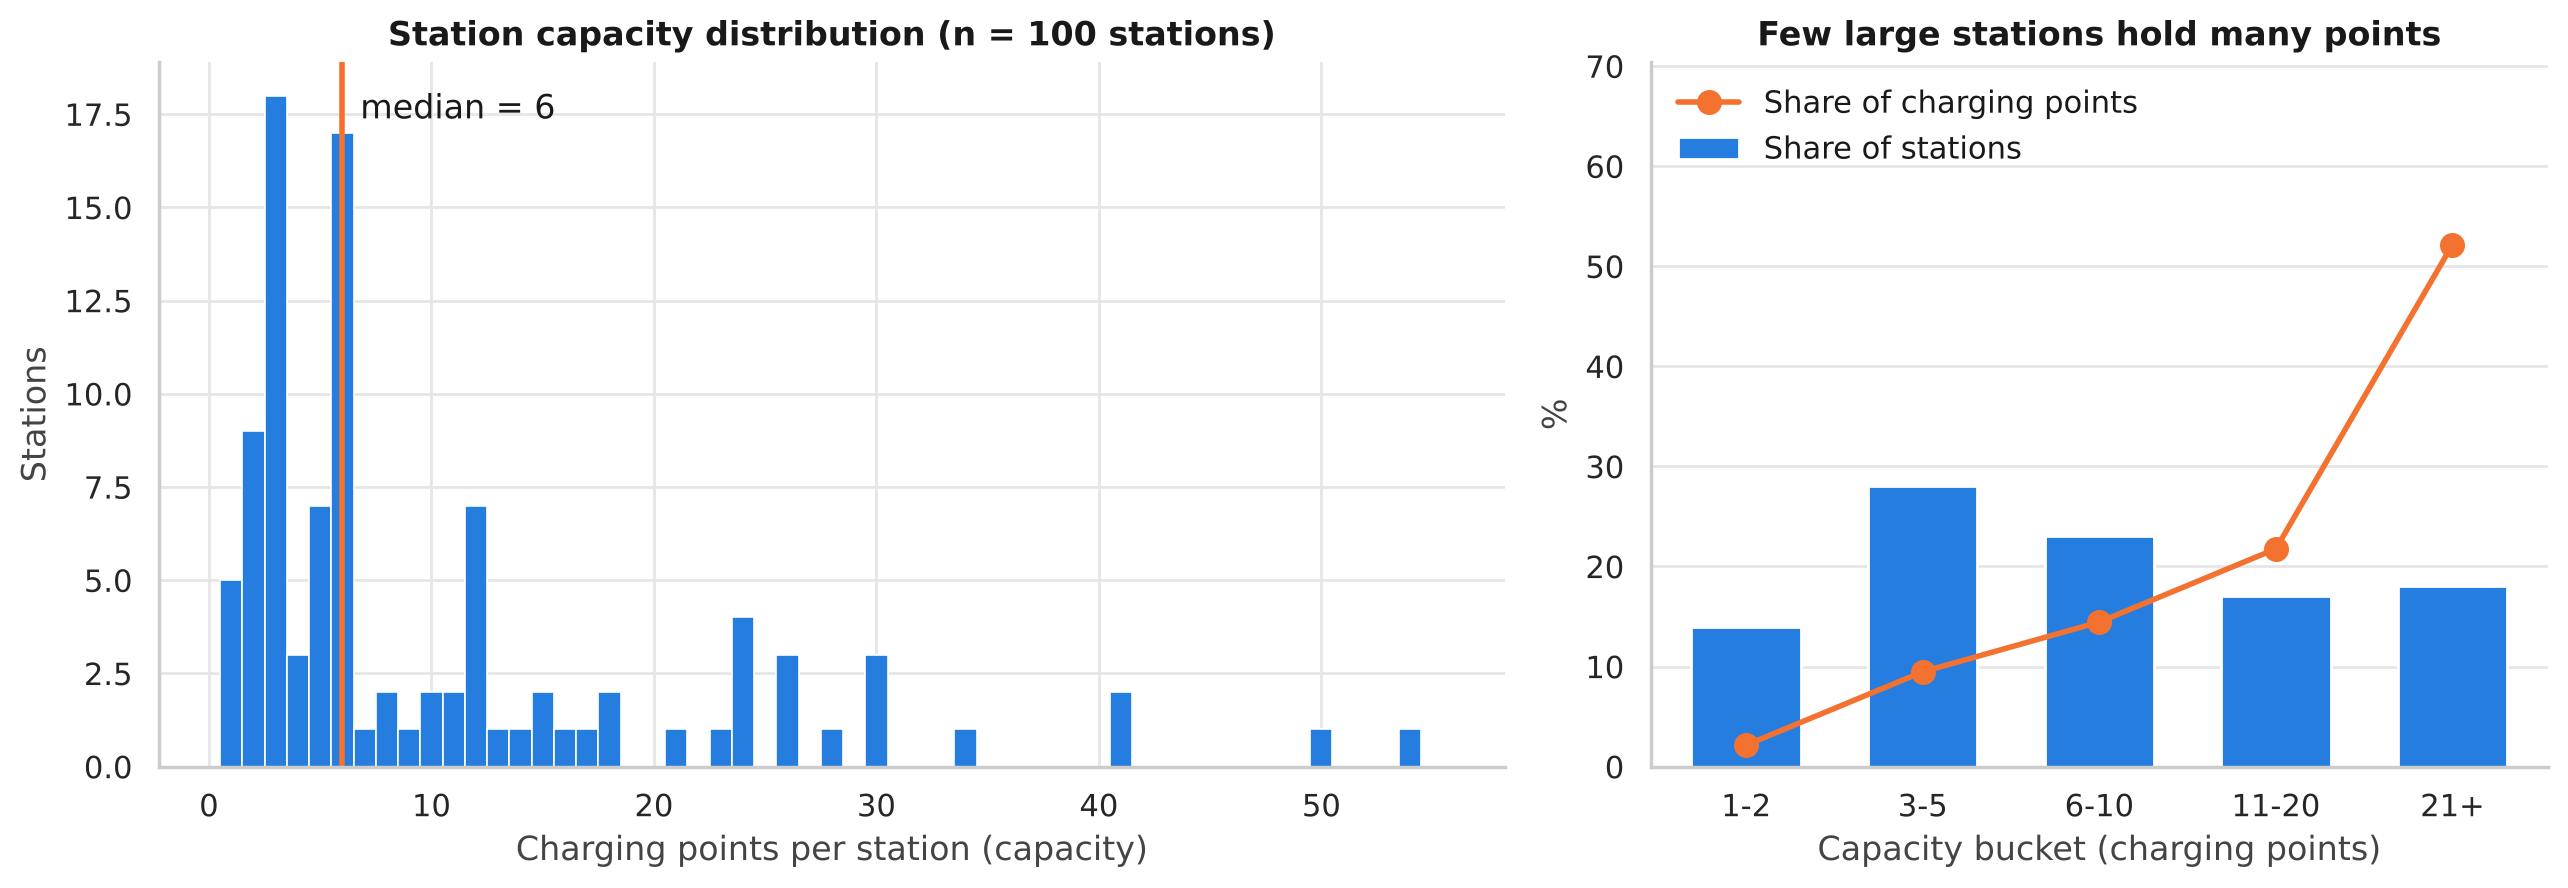

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.hist(cap, bins=np.arange(0.5, cap.max() + 2.5, 1), color=BLUE, edgecolor="white", linewidth=0.6)
ax.axvline(cap.median(), color=ORANGE, linewidth=2)
ax.text(cap.median() + 0.8, ax.get_ylim()[1] * 0.92, f"median = {cap.median():.0f}", color=INK)
ax.set_xlabel("Charging points per station (capacity)"); ax.set_ylabel("Stations")
ax.set_title(f"Station capacity distribution (n = {len(cap)} stations)")

ax = axes[1]
x = cat_table.index.astype(str)
ax.bar(x, cat_table.share_of_stations * 100, color=BLUE, width=0.62, label="Share of stations")
ax.plot(x, cat_table.share_of_points * 100, color=ORANGE, marker="o", markersize=8, linewidth=2, label="Share of charging points")
ax.set_xlabel("Capacity bucket (charging points)"); ax.set_ylabel("%")
ax.set_ylim(0, max(cat_table.share_of_stations.max(), cat_table.share_of_points.max()) * 100 * 1.35)
ax.set_title("Few large stations hold many points"); ax.legend(frameon=False, loc="upper left")
ax.grid(axis="x", visible=False)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "station_capacity_distribution.png")
plt.show()

## 9. Geographic distribution

Bounding box: lon 114.0299 - 114.069 | lat 22.5226 - 22.5551
Extent: about 4.0 km east-west x 3.6 km north-south
Stations sharing exact coordinates with another station: 16 (in 8 locations)


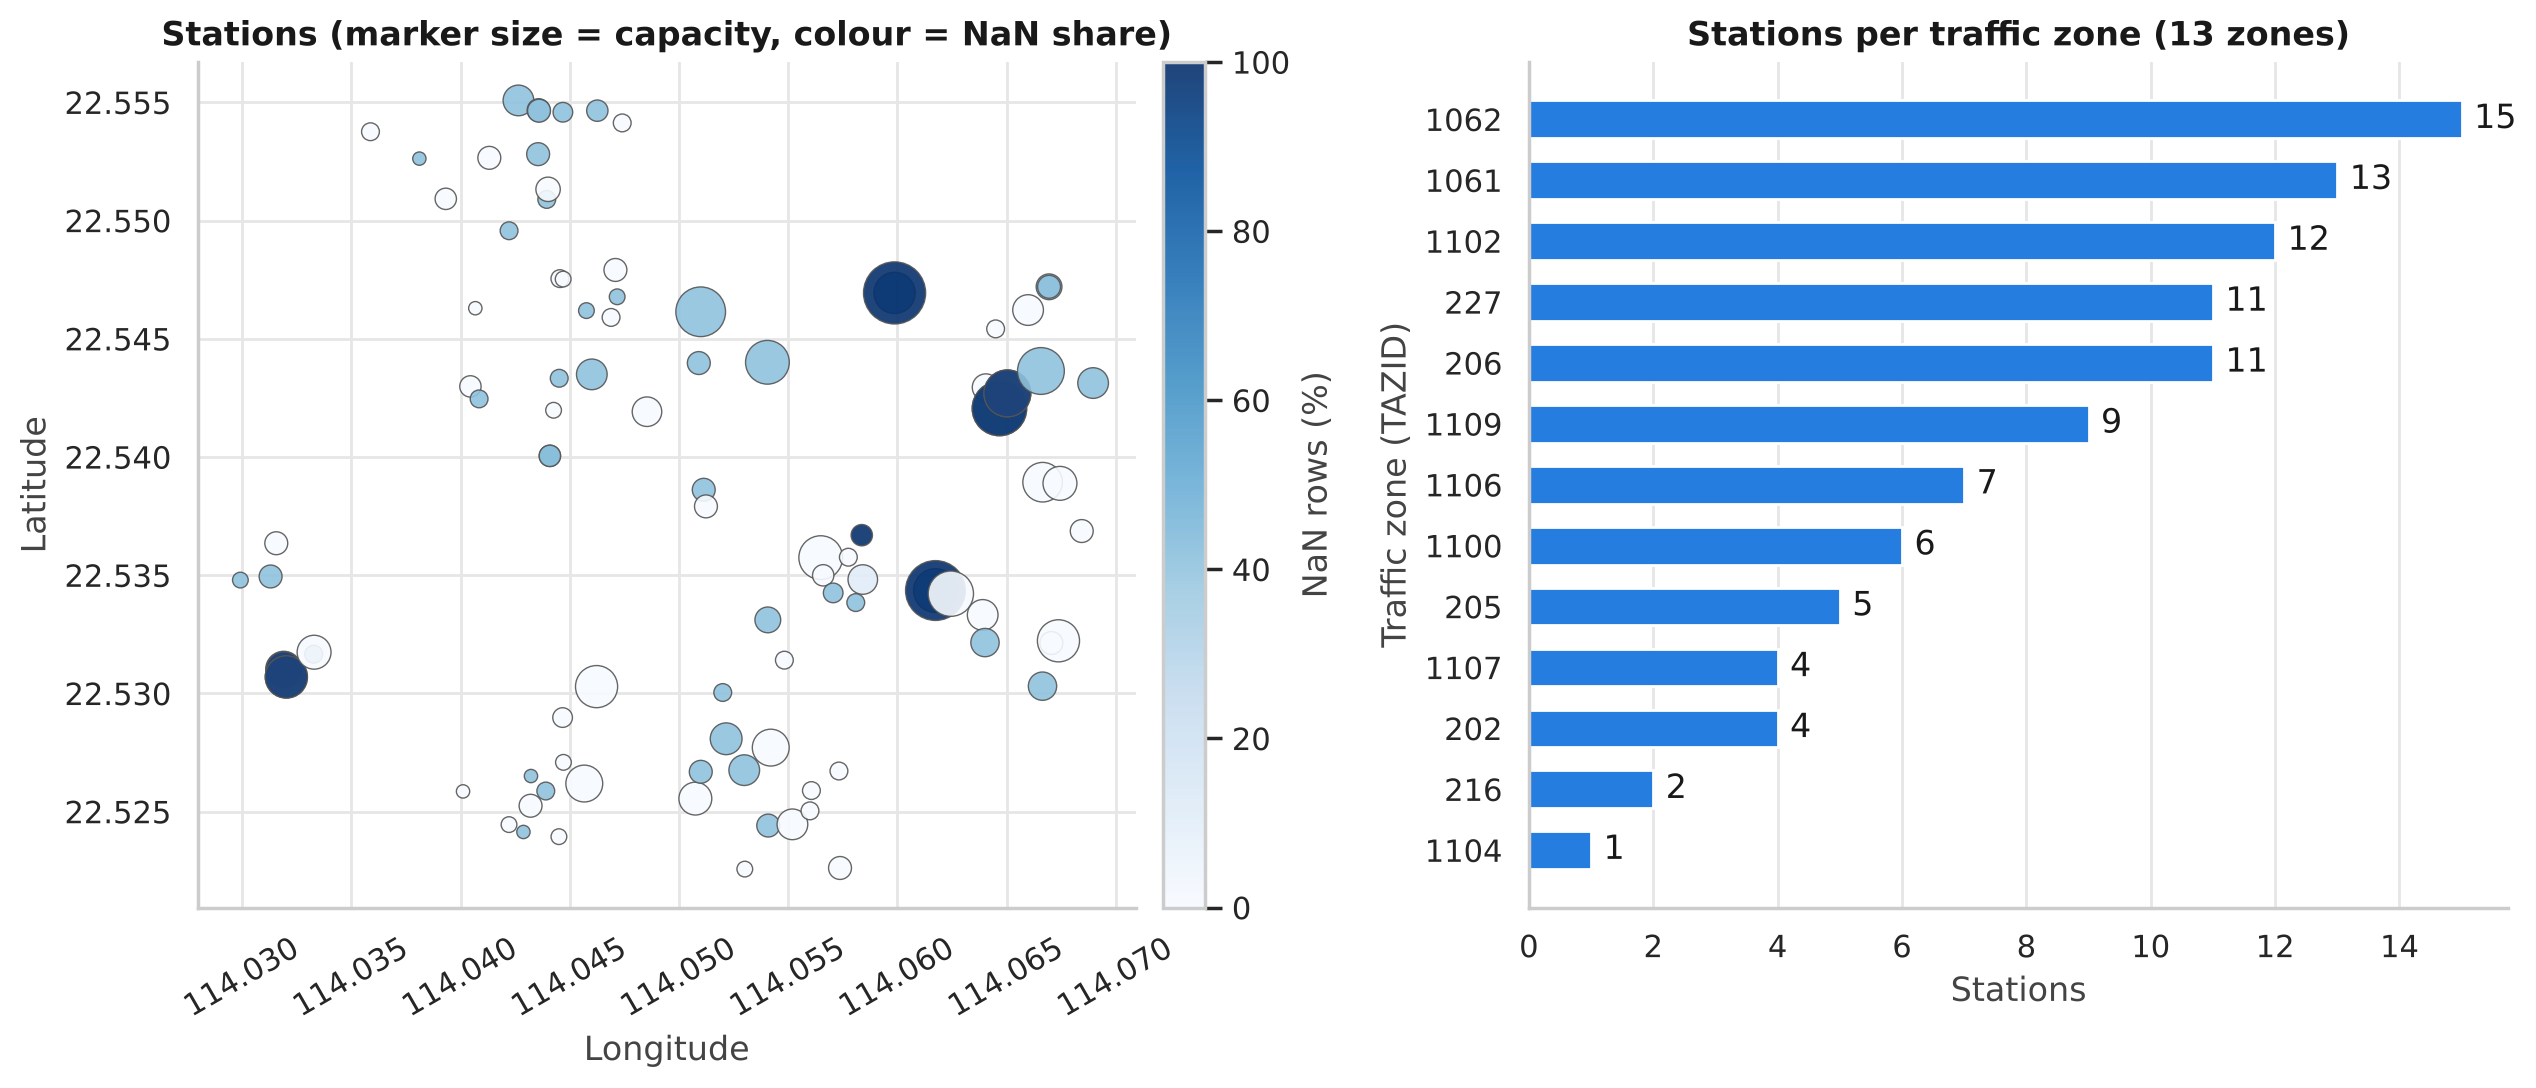

In [19]:
geo = scan.reset_index()
print("Bounding box: lon", round(geo.longitude.min(), 4), "-", round(geo.longitude.max(), 4),
      "| lat", round(geo.latitude.min(), 4), "-", round(geo.latitude.max(), 4))
extent_km = ((geo.longitude.max() - geo.longitude.min()) * 111.32 * np.cos(np.deg2rad(geo.latitude.mean())),
             (geo.latitude.max() - geo.latitude.min()) * 110.57)
print(f"Extent: about {extent_km[0]:.1f} km east-west x {extent_km[1]:.1f} km north-south")
dup_mask = geo.duplicated(["longitude", "latitude"], keep=False)
print("Stations sharing exact coordinates with another station:", int(dup_mask.sum()),
      f"(in {geo[dup_mask].groupby(['longitude', 'latitude']).ngroups} locations)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
sc = ax.scatter(geo.longitude, geo.latitude, s=geo.capacity * 9 + 14, c=geo.nan_share * 100, cmap="Blues", vmin=0, vmax=100,
                edgecolor="#555555", linewidth=0.5, alpha=0.9)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.set_aspect(1 / np.cos(np.deg2rad(geo.latitude.mean())))
ax.ticklabel_format(useOffset=False, style="plain"); ax.tick_params(axis="x", labelrotation=30)
ax.set_title("Stations (marker size = capacity, colour = NaN share)")
cb = fig.colorbar(sc, ax=ax, fraction=0.04, pad=0.02); cb.set_label("NaN rows (%)")
ax = axes[1]
zs = zone_summary.sort_values("stations")
ax.barh(zs.index.astype(str), zs.stations, color=BLUE, height=0.62)
for y, v in enumerate(zs.stations):
    ax.text(v + 0.2, y, str(v), va="center", color=INK)
ax.set_xlabel("Stations"); ax.set_ylabel("Traffic zone (TAZID)"); ax.set_title(f"Stations per traffic zone ({len(zs)} zones)")
ax.grid(axis="y", visible=False)
for a in axes: a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
save_fig(fig, "station_map.png")
plt.show()

## 10. The shared development sample

Everyone can develop on `dl.get_sample_station_ids()` (20 stations, seed 42, only stations with at most 50 % NaN rows) and then run the final analysis on all stations. Let's check that this sample is not misleading.

In [20]:
sample_ids = dl.get_sample_station_ids()
pop = scan[scan.nan_share <= 0.5]
smp = scan.loc[sample_ids]
cmp_s = pd.DataFrame({
    "eligible population (<= 50 % NaN)": [len(pop), pop.capacity.median(), pop.capacity.mean(), pop.capacity.max(), pop.nan_share.median(), pop.mean_occupancy_rate.mean()],
    "shared sample": [len(smp), smp.capacity.median(), smp.capacity.mean(), smp.capacity.max(), smp.nan_share.median(), smp.mean_occupancy_rate.mean()],
}, index=["stations", "median capacity", "mean capacity", "max capacity", "median NaN share", "mean occupancy rate"])
display(cmp_s)
save_table(pd.DataFrame({"station_id": sample_ids}), "sample_stations.csv")
print("Sample IDs:", sample_ids)

,eligible population (<= 50 % NaN),shared sample
stations,90.000,20.000
median capacity,6.000,7.500
mean capacity,8.800,11.000
max capacity,41.000,41.000
median NaN share,0.000,0.000
mean occupancy rate,0.187,0.166


Sample IDs: [1717, 1720, 1761, 1764, 1765, 1774, 1787, 1791, 1793, 1795, 1797, 1803, 1856, 1878, 1888, 1897, 1942, 1948, 1967, 1980]


## 11. Dataset summary table

In [21]:
valid_all = n_valid_total
summary = pd.DataFrame([
    ("General", "Source", "VoltAhead dataset: 100 stations selected from UrbanEV (Shenzhen)"),
    ("General", "Files", f"{dl.STATIONS_FILE} ({len(info)} rows), {dl.DATA_FILE} ({len(stored):,} rows)"),
    ("General", "Period", f"{GRID[0]:%Y-%m-%d} to {GRID[-1]:%Y-%m-%d} ({N_DAYS} days)"),
    ("General", "Resolution / time steps per station", f"5 minutes / {N_STEPS:,}"),
    ("Stations", "Stations", f"{len(info)}"),
    ("Stations", "Traffic zones", f"{info.TAZID.nunique()}"),
    ("Stations", "Charging points (sum of charge_count)", f"{int(info.charge_count.sum()):,}"),
    ("Stations", "  slow / fast points", f"{int(info.slow_count.sum()):,} / {int(info.fast_count.sum()):,}"),
    ("Stations", "Capacity: median / mean / max (points per station)", f"{cap.median():.0f} / {cap.mean():.1f} / {cap.max()}"),
    ("Stations", "distance_km: min / max", f"{info.distance_km.min():.2f} / {info.distance_km.max():.2f}"),
    ("Observations", "Station-timestamp rows", f"{total_rows:,}"),
    ("Observations", "Rows with real observations", f"{valid_all:,} ({valid_all/total_rows:.1%})"),
    ("Observations", "All-NaN rows (missing observations)", f"{all_na_rows:,} ({all_na_rows/total_rows:.1%})"),
    ("Observations", "Duplicated timestamps / missing timestamps", f"{int(scan.n_dup_ts.sum())} / {int(scan.n_missing_ts.sum())}"),
    ("Observations", "Stations with 0 % / > 25 % / 100 % NaN rows", f"{int((scan.nan_share == 0).sum())} / {int((scan.nan_share > 0.25).sum())} / {int((scan.n_valid == 0).sum())}"),
    ("Observations", "Stations reporting on the last day", f"{int(scan.reports_on_last_day.sum())}"),
    ("Consistency", "busy + idle == charge_count", "holds in 100 % of valid rows" if int(scan.n_total_ne_cap.sum()) == 0 else "VIOLATED, see section 6"),
], columns=["section", "metric", "value"])
dataset_summary = save_table(summary, "dataset_summary.csv")
dataset_summary

,section,metric,value
0,General,Source,VoltAhead dataset: 100 stations selected from ...
1,General,Files,"selected_stations.csv (100 rows), selected_sta..."
2,General,Period,2022-12-01 to 2023-02-28 (90 days)
3,General,Resolution / time steps per station,"5 minutes / 25,920"
4,Stations,Stations,100
5,Stations,Traffic zones,13
6,Stations,Charging points (sum of charge_count),"1,066"
7,Stations,slow / fast points,"1,064 / 2"
8,Stations,Capacity: median / mean / max (points per stat...,6 / 10.7 / 54
9,Stations,distance_km: min / max,0.19 / 2.14


## 12. Key findings and implications for machine learning

**Findings**

1. **Structure is clean.** 100 stations x 25,920 five-minute steps (2022-12-01 to 2023-02-28) = 2,592,000 rows. No duplicated or missing timestamps, no unsorted rows, and the static columns in the big file match `selected_stations.csv` for every station.
2. **But 25.5 % of the rows are all-NaN** (660,016 rows): a missing observation is a row where all 10 value columns are NaN at once. 44 stations are complete, 50 stations have more than 25 % NaN rows, and 1 station never reports. Of the NaN rows, 62 % are interior gaps, 22 % leading (station not yet reporting) and 16 % trailing (station stopped reporting). A one-time cross-check against the original UrbanEV station files showed that the `busy` series of all 100 stations is identical to the original, so these gaps come from the source data, not from the extraction.
3. **Gaps are long, not blips.** There are 358 interior gaps with a median length of 1,291 steps (4.5 days); only 20 of them are shorter than an hour, 45 last at least a week, and 42 stations have such a week-long gap.
4. **One system-wide event splits the period.** On **2023-01-22 the share of stations that report drops from 90 % to 52 % and never recovers.** The NaN share is 9.5 % in December, 22.3 % in January and 46.6 % in February; 9.8 % before the event versus 46.9 % after it. 48 stations are more than 50 % NaN from that date on, and only 52 stations report on the last day.
5. **busy / idle / capacity are perfectly consistent.** `busy + idle = charge_count` in all 1,931,984 valid rows, with no negative or non-integer values and a fast/slow split that matches the metadata.
6. **Small, slow-charging stations.** 1,066 charging points, median capacity 6 (mean 10.7, max 54). The 18 stations with 21+ points hold 52 % of all points, while the 14 stations with 1-2 points hold 2 %. Only 2 of the 1,066 points are fast chargers (one station).
7. **Compact area.** All stations lie in about 4.0 km x 3.6 km, in 13 traffic zones; `distance_km` ranges from 0.19 to 2.14 km (distance to a reference point that is not in the files). 16 stations share exact coordinates with another station (8 locations).
8. **Usage is low.** Over valid observations the mean occupancy rate is 19.5 %, stations are completely empty 44 % of the time and completely full only 4 % of the time.
9. **Prices are almost constant within a station:** `s_price` changes over time at 8 stations and `e_price` at 9.
10. **Missingness is not independent of station size:** a station's NaN share correlates with its capacity (r = 0.38) but not with `distance_km` (r = -0.05).

**Implications for Step 2 (modelling)**

* **Never train or evaluate on NaN rows.** Build the target only from valid rows (`dl.valid_mask`). Do not forward-fill or interpolate across the gaps: they last days, not minutes.
* **Agree on one time window for the whole team.** Reporting is reliable (about 90 % of stations) only from 2022-12-01 to 2023-01-21 (52 days). From 2023-01-22 half of the stations are silent, so a test period taken from the end of the data would be mostly empty and its metrics would describe a biased set of stations. Options: (a) use the first 52 days and split by time inside them; (b) keep the full period but only the 52 stations that report until the end (505 points, see `station_coverage_filters.csv`); (c) use all rows but always report the number of valid observations per station and split.
* **Split by time, not at random,** and use the same split for everyone.
* **Target:** occupancy rate (`busy / charge_count`) or availability (`idle`); the exact identity `busy + idle = capacity` means either can be derived from the other. "Completely full" is rare (4 %), so a full / not-full target would be very imbalanced.
* **Use capacity as a static feature.** With a median of 6 points, the occupancy rate is coarse for small stations (a 1-point station is either 0 or 100 %); do not average rates across stations without weighting by capacity.
* **Drop the fast/slow columns** (`fast_busy`, `fast_idle`, `fast_count`): they carry no information with only 2 fast points; the slow columns equal the totals.
* **Price columns** are close to constant within a station, so they behave like static station features rather than time-varying signals.
* **Treat `distance_km` and `TAZID` carefully.** `distance_km` reflects how the 100 stations were selected, not charging behaviour. `TAZID` (13 zones) can be used for zone-level aggregation.
* **Development sample:** `dl.get_sample_station_ids()` (20 stations with at most 50 % NaN rows) is fine for testing code; the final analysis should use all stations.